# Model 2: Naive Bayes (Gaussian), Red Wine Quality

Predict **Good Quality (1)** (quality ≥ 6) or **Lower Quality (0)** (quality < 6) from the 11 chemical properties.
Stratified 80/20 split of all 1,599 red wines (duplicates kept).

In [1]:
import warnings

warnings.filterwarnings('ignore')

# core data handling & numerical operations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# from scikit-learn
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    log_loss,
    make_scorer,
    classification_report,
    confusion_matrix,
)

from google.colab import files

# settings
SEED = 42
TEST_SIZE = 0.2
# agree as a group: the red wine file has 240 duplicate rows
DROP_DUPLICATES = False

np.random.seed(SEED)  # (reproducibility)

Upload the red wine csv file

In [2]:
uploaded = files.upload()

# Load the red wine dataset
df_red = pd.read_csv('winequality-red.csv', sep=';')
print("Red wine loaded! Shape:", df_red.shape)
print("Duplicates:", df_red.duplicated().sum())  # check duplicates
print(
    "Missing values:", df_red.isnull().sum().sum()
)  # check missing values

if DROP_DUPLICATES:
    df_red = df_red.drop_duplicates().reset_index(drop=True)
    print("After dropping duplicates:", df_red.shape)

Saving winequality-red.csv to winequality-red.csv
Red wine loaded! Shape: (1599, 12)
Duplicates: 240
Missing values: 0


Binary target: quality ≥ 6 → Good (1), quality < 6 → Lower (0)

In [3]:
print("Number of records per class 'quality'")
print(df_red.groupby('quality').size())

target_column = 'quality'
X = df_red.drop(columns=[target_column])
y = (df_red[target_column] >= 6).astype(int)  # 1 = Good, 0 = Lower

print("\nBinary classes:")
print(
    y.value_counts()
    .sort_index()
    .rename({0: 'Lower (0)', 1: 'Good (1)'})
)
print(
    "Good share:", round(y.mean(), 3)
)  # close to balanced, so accuracy is meaningful

Number of records per class 'quality'
quality
3     10
4     53
5    681
6    638
7    199
8     18
dtype: int64

Binary classes:
quality
Lower (0)    744
Good (1)     855
Name: count, dtype: int64
Good share: 0.535


using stratified split, Training dataset(80%), Testing dataset(20%)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
)

print(
    f"Train: {len(X_train)} wines, Good share = {y_train.mean():.3f}"
)
print(
    f"Test:  {len(X_test)} wines, Good share = {y_test.mean():.3f}"
)

Train: 1279 wines, Good share = 0.535
Test:  320 wines, Good share = 0.534


How Gaussian Naive Bayes works

**Bayes' rule:** P(c | x) = P(c) × P(x | c) / P(x)

**Naive assumption** (features independent given the class): P(x | c) = P(x₁ | c) × P(x₂ | c) × … × P(x₁₁ | c).
This is the simplest Bayesian network (Lecture 7): the class node is the only parent of every feature node,
with no edges between features.

**Gaussian likelihood:** P(xᵢ | c) = 1 / √(2πσ²) × exp( −(xᵢ − μ)² / (2σ²) ), where μ and σ² are the mean and
variance of feature i in class c.

**Decision rule:** ĉ = argmax over c of [ log P(c) + Σᵢ log P(xᵢ | c) ]. P(x) is the same for both classes, so it is
ignored, and logs avoid multiplying many small numbers.

- Training only estimates P(c) and the per-class mean μ and variance σ² of each feature. This is closed-form, with no gradient descent or hyperparameter tuning.
- No feature scaling is needed. Multiplying a feature by k multiplies its mean and standard deviation in both classes by k, so the comparison between classes does not change.

Train the model

In [5]:
nb = GaussianNB()
nb.fit(X_train, y_train)

print(
    "Class priors P(c):",
    dict(zip(['Lower (0)', 'Good (1)'], nb.class_prior_.round(3))),
)

# learned parameters: per-class mean and std of every feature
params = pd.DataFrame(
    {
        'mean | Lower': nb.theta_[0],
        'mean | Good': nb.theta_[1],
        'std | Lower': np.sqrt(nb.var_[0]),
        'std | Good': np.sqrt(nb.var_[1]),
    },
    index=X.columns,
)

# separation = gap between the class means, in pooled std
# (bigger = more useful feature)
params['separation'] = (
    params['mean | Good'] - params['mean | Lower']
) / np.sqrt((nb.var_[0] + nb.var_[1]) / 2)
params.round(3).sort_values('separation', key=abs, ascending=False)

Class priors P(c): {'Lower (0)': np.float64(0.465), 'Good (1)': np.float64(0.535)}


,mean | Lower,mean | Good,std | Lower,std | Good,separation
alcohol,9.950,10.860,0.772,1.116,0.949
volatile acidity,0.587,0.473,0.179,0.160,-0.675
sulphates,0.618,0.693,0.173,0.149,0.463
total sulfur dioxide,54.409,39.482,36.689,28.000,-0.457
citric acid,0.241,0.300,0.181,0.200,0.310
density,0.997,0.996,0.002,0.002,-0.279
chlorides,0.092,0.082,0.055,0.037,-0.215
fixed acidity,8.165,8.489,1.575,1.888,0.187
free sulfur dioxide,16.432,15.336,10.332,10.089,-0.107
residual sugar,2.518,2.559,1.276,1.466,0.030


Alcohol (higher in good wines), volatile acidity (lower in good wines) and sulphates separate the classes best.

Worked example: classifying one wine by hand

In [6]:
x = X_test.iloc[0]


# log of the Gaussian density for each feature
def log_gauss(v, mu, var):
    return -0.5 * np.log(2 * np.pi * var) - (v - mu) ** 2 / (
        2 * var
    )


ll_lower = log_gauss(x.values, nb.theta_[0], nb.var_[0])
ll_good = log_gauss(x.values, nb.theta_[1], nb.var_[1])

steps = pd.DataFrame(
    {
        'value': x.values,
        'log P(x_i | Lower)': ll_lower,
        'log P(x_i | Good)': ll_good,
        'evidence for Good': ll_good - ll_lower,
    },
    index=X.columns,
)
display(steps.round(3))

# add the log prior, then turn the two scores into a probability
score_lower = np.log(nb.class_prior_[0]) + ll_lower.sum()
score_good = np.log(nb.class_prior_[1]) + ll_good.sum()
p_good = 1 / (1 + np.exp(score_lower - score_good))

print(f"log P(Lower) + sum = {score_lower:.3f}")
print(f"log P(Good)  + sum = {score_good:.3f}")
print(f"P(Good | x) by hand      = {p_good:.4f}")
p_sklearn = nb.predict_proba(x.to_frame().T)[0, 1]
print(f"P(Good | x) scikit-learn = {p_sklearn:.4f}")  # should match

pred_label = 'Good' if p_good >= 0.5 else 'Lower'
true_label = 'Good' if y_test.iloc[0] else 'Lower'
grade0 = df_red.loc[x.name, 'quality']
print(
    f"Predicted: {pred_label} | Actual: {true_label} (grade {grade0})"
)

,value,log P(x_i | Lower),log P(x_i | Good),evidence for Good
fixed acidity,8.300,-1.377,-1.559,-0.182
volatile acidity,0.610,0.793,0.544,-0.249
citric acid,0.300,0.739,0.689,-0.050
residual sugar,2.100,-1.216,-1.351,-0.134
chlorides,0.084,1.980,2.384,0.405
free sulfur dioxide,11.000,-3.392,-3.323,0.070
total sulfur dioxide,50.000,-4.529,-4.322,0.207
density,0.997,5.337,5.078,-0.259
pH,3.400,0.806,0.775,-0.031
sulphates,0.610,0.832,0.826,-0.005


log P(Lower) + sum = -1.506
log P(Good)  + sum = -2.087
P(Good | x) by hand      = 0.3585
P(Good | x) scikit-learn = 0.3585
Predicted: Lower | Actual: Good (grade 6)


Each value in **evidence for Good** is one feature's vote. Naive Bayes just adds the votes, so features that carry the same information get counted twice.

Final Evaluation

Metrics

- **Accuracy:** share of test wines classified correctly.
- **Balanced accuracy:** the average of the recall for each class, so the bigger class cannot dominate. A model that always predicts one class scores 0.5.
- **Precision / recall:** for the Good class.
- **Macro F1:** F1 is computed for each class and then averaged, so Lower and Good count equally.
- **QWK (quadratic weighted kappa):** agreement with the true labels after removing the agreement expected by chance. 0 means no better than chance and 1 means perfect. With only 2 classes the quadratic weights change nothing, so QWK equals Cohen's kappa.
- **Log loss:** −mean[ y·log p + (1 − y)·log(1 − p) ], where p = P(Good). Lower is better. It punishes confident wrong predictions heavily, so it checks the probabilities and not just the labels.

In [7]:
y_pred = nb.predict(X_test)
y_prob = nb.predict_proba(X_test)[:, 1]  # P(Good)


def scores(y_true, y_hat, p_good):
    return {
        'accuracy': accuracy_score(y_true, y_hat),
        'balanced accuracy': balanced_accuracy_score(y_true, y_hat),
        'precision': precision_score(y_true, y_hat),
        'recall': recall_score(y_true, y_hat),
        'macro F1': f1_score(y_true, y_hat, average='macro'),
        'QWK': cohen_kappa_score(
            y_true, y_hat, weights='quadratic'
        ),
        'log loss': log_loss(y_true, p_good),
    }


print(
    pd.Series(scores(y_test, y_pred, y_prob)).round(3).to_string()
)
print()
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Lower (0)', 'Good (1)'],
        digits=3,
    )
)

accuracy             0.725
balanced accuracy    0.728
precision            0.779
recall               0.678
macro F1             0.725
QWK                  0.453
log loss             0.771

              precision    recall  f1-score   support

   Lower (0)      0.678     0.779     0.725       149
    Good (1)      0.779     0.678     0.725       171

    accuracy                          0.725       320
   macro avg      0.728     0.728     0.725       320
weighted avg      0.732     0.725     0.725       320



Majority-class baseline

The simplest possible model: always predict the bigger class (Good) and give every wine the training share of Good wines as its probability. Any useful model has to beat this.

In [8]:
# strategy='prior': predicts the majority class, and the
# probabilities are the class shares ('most_frequent' would give
# 0/1 probabilities and an infinite log loss)
baseline = DummyClassifier(strategy='prior')
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)
base_prob = baseline.predict_proba(X_test)[:, 1]

pd.DataFrame(
    {
        'Majority baseline': scores(y_test, base_pred, base_prob),
        'Naive Bayes': scores(y_test, y_pred, y_prob),
    }
).round(3)

,Majority baseline,Naive Bayes
accuracy,0.534,0.725
balanced accuracy,0.500,0.728
precision,0.534,0.779
recall,1.000,0.678
macro F1,0.348,0.725
QWK,0.000,0.453
log loss,0.691,0.771


- Naive Bayes clearly beats the baseline on accuracy (0.725 vs 0.534), balanced accuracy (0.728 vs 0.500), macro F1 (0.725 vs 0.348) and QWK (0.453 vs 0). The baseline's recall of 1.0 only comes from calling every wine Good.
- Its **log loss is worse than the baseline's** (0.771 vs 0.691). When Naive Bayes is wrong it is often very confident, and log loss punishes that heavily. The independence check below explains why.

Confusion Matrix

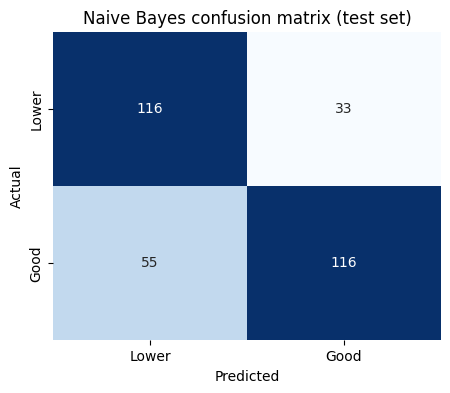

In [9]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=['Lower', 'Good'],
    yticklabels=['Lower', 'Good'],
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Naive Bayes confusion matrix (test set)')
plt.show()

Actual vs Predicted (first 15 test wines)

In [10]:
results = pd.DataFrame(
    {
        'quality grade': df_red.loc[X_test.index, 'quality'].values,
        'actual': np.where(y_test == 1, 'Good', 'Lower'),
        'predicted': np.where(y_pred == 1, 'Good', 'Lower'),
        'P(Good)': y_prob.round(3),
    },
    index=X_test.index,
)
results['correct'] = results['actual'] == results['predicted']
results.head(15)

,quality grade,actual,predicted,P(Good),correct
100,6,Good,Lower,0.359,False
1391,5,Lower,Good,0.596,False
170,4,Lower,Lower,0.016,True
461,5,Lower,Lower,0.270,True
346,7,Good,Good,0.952,True
1126,6,Good,Good,1.000,True
860,5,Lower,Lower,0.070,True
1363,4,Lower,Lower,0.053,True
776,6,Good,Lower,0.001,False
1440,7,Good,Good,0.951,True


Cross-validation (5-fold, training set only)

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scoring = {
    'accuracy': 'accuracy',
    'balanced accuracy': 'balanced_accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'macro F1': 'f1_macro',
    'QWK': make_scorer(cohen_kappa_score, weights='quadratic'),
    'log loss': 'neg_log_loss',
}
cv_res = cross_validate(
    GaussianNB(), X_train, y_train, cv=cv, scoring=cv_scoring
)

cv_table = pd.DataFrame(
    {m: cv_res[f'test_{m}'] for m in cv_scoring}
)
cv_table['log loss'] *= -1  # scikit-learn returns it negated
# std over the 5 folds (same as the ± in the comparison below)
pd.DataFrame(
    {'mean': cv_table.mean(), 'std': cv_table.std(ddof=0)}
).round(3)

,mean,std
accuracy,0.719,0.030
balanced accuracy,0.719,0.029
precision,0.749,0.030
recall,0.714,0.049
macro F1,0.718,0.029
QWK,0.436,0.058
log loss,0.802,0.170


A small std means the result does not depend on one lucky split. The test set is never used here.

Independence assumption check

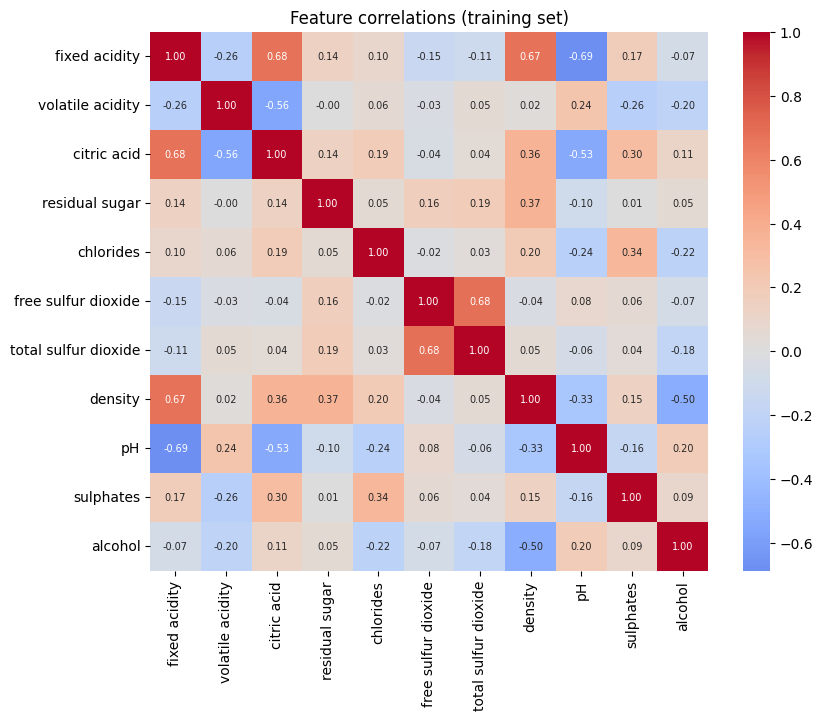

,feature 1,feature 2,correlation
0,fixed acidity,citric acid,0.68
1,fixed acidity,density,0.67
2,fixed acidity,pH,-0.69
3,volatile acidity,citric acid,-0.56
4,citric acid,pH,-0.53
5,free sulfur dioxide,total sulfur dioxide,0.68
6,density,alcohol,-0.50


In [12]:
corr = X_train.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 7},
)
plt.title('Feature correlations (training set)')
plt.show()

# strongly correlated pairs break the independence assumption
pairs = [
    (a, b, round(corr.loc[a, b], 2))
    for i, a in enumerate(corr.columns)
    for b in corr.columns[i + 1 :]
    if abs(corr.loc[a, b]) >= 0.5
]
pd.DataFrame(
    pairs, columns=['feature 1', 'feature 2', 'correlation']
)

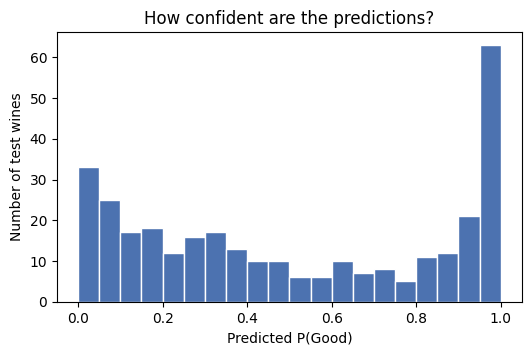

Predictions below 0.1 or above 0.9: 44.4%
Test accuracy: 72.5%


In [13]:
plt.figure(figsize=(6, 3.5))
plt.hist(y_prob, bins=20, color='#4c72b0', edgecolor='white')
plt.xlabel('Predicted P(Good)')
plt.ylabel('Number of test wines')
plt.title('How confident are the predictions?')
plt.show()

extreme = ((y_prob < 0.1) | (y_prob > 0.9)).mean()
acc = accuracy_score(y_test, y_pred)
print(f"Predictions below 0.1 or above 0.9: {extreme:.1%}")
print(f"Test accuracy: {acc:.1%}")

Several chemical properties are strongly correlated, so the independence assumption is violated. The same evidence gets
counted more than once, which pushes P(Good) towards 0 or 1: the model is far more confident than its accuracy. This is also why its log loss is worse than the majority baseline.
Classification can still work, because only the side of 0.5 matters for the decision.

Gaussian assumption check

,skewness
chlorides,5.64
residual sugar,4.50
sulphates,2.24
total sulfur dioxide,1.62
free sulfur dioxide,1.19
fixed acidity,0.95
alcohol,0.87
volatile acidity,0.72
citric acid,0.27
pH,0.19


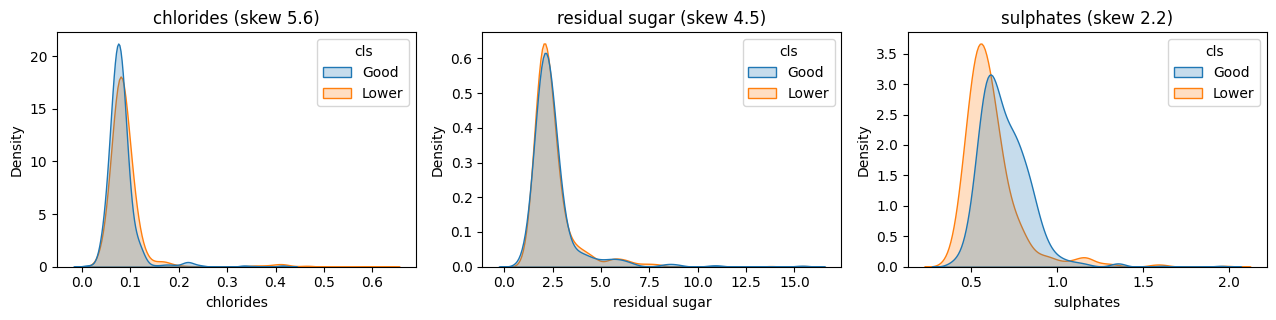

In [14]:
skew = X_train.skew().sort_values(ascending=False)
display(skew.round(2).to_frame('skewness'))

# the 3 most skewed features, split by class
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, col in zip(axes, skew.index[:3]):
    sns.kdeplot(
        data=X_train.assign(
            cls=np.where(y_train == 1, 'Good', 'Lower')
        ),
        x=col,
        hue='cls',
        common_norm=False,
        fill=True,
        ax=ax,
    )
    ax.set_title(f"{col} (skew {skew[col]:.1f})")
plt.tight_layout()
plt.show()

Chlorides, residual sugar and sulphates are strongly right-skewed, so one Gaussian per class is only a rough fit for them.

Fixing the assumptions (compare 3 versions)

- **A. All features:** plain Gaussian NB on all 11 features
- **B. Log-transform the skewed features**, to make them more Gaussian
- **C. Drop correlated features** (fixed acidity, free sulfur dioxide, density), to reduce double counting

The versions are compared with cross-validation on the training set, then each is scored on the test set.

In [15]:
skewed = list(skew[skew > 1].index)
redundant = ['fixed acidity', 'free sulfur dioxide', 'density']

variants = {
    'A. All features': make_pipeline(GaussianNB()),
    'B. Log-transform skewed': make_pipeline(
        ColumnTransformer(
            [('log', FunctionTransformer(np.log1p), skewed)],
            remainder='passthrough',
        ),
        GaussianNB(),
    ),
    'C. Drop correlated': make_pipeline(
        ColumnTransformer(
            [('drop', 'drop', redundant)], remainder='passthrough'
        ),
        GaussianNB(),
    ),
}

rows = {}
for name, model in variants.items():
    r = cross_validate(
        model, X_train, y_train, cv=cv, scoring=cv_scoring
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    acc_cv = r['test_accuracy']
    f1_cv = r['test_macro F1']
    ll_cv = -r['test_log loss']
    test_scores = scores(y_test, pred, prob)
    extreme_share = ((prob < 0.1) | (prob > 0.9)).mean()
    rows[name] = {
        'CV accuracy': f"{acc_cv.mean():.3f} ± {acc_cv.std():.3f}",
        'CV macro F1': f"{f1_cv.mean():.3f} ± {f1_cv.std():.3f}",
        'CV log loss': f"{ll_cv.mean():.3f} ± {ll_cv.std():.3f}",
        **{f'test {k}': f"{v:.3f}" for k, v in test_scores.items()},
        'extreme probs': f"{extreme_share:.0%}",
    }
comparison = pd.DataFrame(rows)  # one column per version
comparison

,A. All features,B. Log-transform skewed,C. Drop correlated
CV accuracy,0.719 ± 0.030,0.726 ± 0.042,0.725 ± 0.022
CV macro F1,0.718 ± 0.029,0.726 ± 0.042,0.723 ± 0.022
CV log loss,0.802 ± 0.170,0.740 ± 0.121,0.750 ± 0.132
test accuracy,0.725,0.713,0.731
test balanced accuracy,0.728,0.717,0.732
test precision,0.779,0.776,0.761
test recall,0.678,0.649,0.725
test macro F1,0.725,0.712,0.731
test QWK,0.453,0.429,0.462
test log loss,0.771,0.720,0.713


- On cross-validation the three versions are within about one std of each other (CV macro F1 0.718 to 0.726), so none is clearly better at the labels.
- Fixing the assumptions helps the **probabilities** more than the labels. CV log loss drops from 0.802 (A) to 0.740 (B) and 0.750 (C).
- **C (drop correlated)** is the most stable across folds and gives the fewest over-confident predictions (35% vs 44%), which supports the independence argument above.
- **A** is kept as the main Naive Bayes result for the group table because it uses the same 11 features as the LR and ANN models. The test set was not used to choose between versions.

Marginal cases (quality grade 5 and 6)

,wines,error rate
quality,,
3,2,0.000
4,15,0.267
5,132,0.220
6,136,0.375
7,31,0.129
8,4,0.000


88 misclassified wines, 91% graded 5 or 6


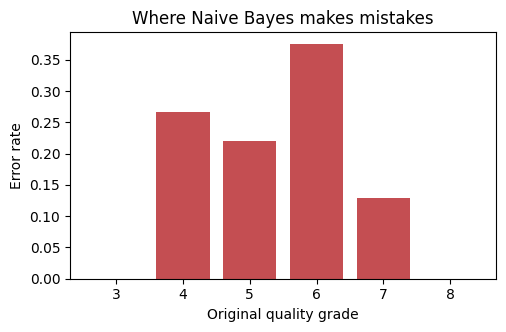

In [16]:
grade = df_red.loc[X_test.index, 'quality']
wrong = pd.Series(y_pred != y_test.values, index=X_test.index)

by_grade = pd.DataFrame(
    {
        'wines': grade.value_counts().sort_index(),
        'error rate': wrong.groupby(grade).mean().round(3),
    }
)
display(by_grade)

share_56 = wrong[grade.isin([5, 6])].sum() / wrong.sum()
n_wrong = wrong.sum()
print(
    f"{n_wrong} misclassified wines, {share_56:.0%} graded 5 or 6"
)

plt.figure(figsize=(5.5, 3.2))
plt.bar(
    by_grade.index.astype(str),
    by_grade['error rate'],
    color='#c44e52',
)
plt.xlabel('Original quality grade')
plt.ylabel('Error rate')
plt.title('Where Naive Bayes makes mistakes')
plt.show()

The cut-off at 6 splits two neighbouring grades. Grade-5 and grade-6 wines are chemically similar but get opposite labels,
so their Gaussian likelihoods overlap and the evidence sum is close to zero. This is where most errors happen.

Summary for the group comparison

In [17]:
base_scores = pd.Series(scores(y_test, base_pred, base_prob))
summary = comparison.loc[['test ' + m for m in base_scores.index]]
summary.index = base_scores.index
summary.insert(
    0, 'Majority baseline', base_scores.map('{:.3f}'.format)
)
summary

,Majority baseline,A. All features,B. Log-transform skewed,C. Drop correlated
accuracy,0.534,0.725,0.713,0.731
balanced accuracy,0.500,0.728,0.717,0.732
precision,0.534,0.779,0.776,0.761
recall,1.000,0.678,0.649,0.725
macro F1,0.348,0.725,0.712,0.731
QWK,0.000,0.453,0.429,0.462
log loss,0.691,0.771,0.720,0.713


**Strengths:** simple, fast and closed-form (no tuning, no scaling); interpretable, since each prediction is a sum of per-feature evidence; stable across folds.

**Weaknesses:** correlated features break the independence assumption, giving over-confident probabilities (log loss worse than the majority baseline); one Gaussian fits the skewed features poorly; struggles with the marginal grade-5 and grade-6 wines.